# 2. Model Training

#### 1.1 Import Data and Required Packages
##### Importing Pandas, Numpy, Matplotlib, Seaborn and Warings Library.

In [1]:
# Basic Import
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
# Modelling
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import RandomizedSearchCV
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
import warnings

In [2]:
df = pd.read_csv('data/stud.csv')
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,associate's degree,free/reduced,none,49,55,62
1,male,group C,associate's degree,free/reduced,completed,34,25,35
2,male,group E,bachelor's degree,standard,completed,89,75,64
3,male,group D,associate's degree,standard,none,92,84,84
4,female,group D,associate's degree,standard,none,73,80,75


#### Preparing X and Y variables

In [3]:
X = df.drop(columns=['math_score'], axis=1)
X.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,reading_score,writing_score
0,female,group B,associate's degree,free/reduced,none,55,62
1,male,group C,associate's degree,free/reduced,completed,25,35
2,male,group E,bachelor's degree,standard,completed,75,64
3,male,group D,associate's degree,standard,none,84,84
4,female,group D,associate's degree,standard,none,80,75


In [4]:
y = df['math_score']
y

0      49
1      34
2      89
3      92
4      73
       ..
995    87
996    95
997    58
998    78
999    72
Name: math_score, Length: 1000, dtype: int64

In [5]:
# Create Column Transformer with 3 types of transformers
num_features = X.select_dtypes(exclude="object").columns
cat_features = X.select_dtypes(include="object").columns

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

numeric_transformer = StandardScaler()
oh_transformer = OneHotEncoder()

preprocessor = ColumnTransformer(
    [
        ("OneHotEncoder", oh_transformer, cat_features),
        ("StandardScaler", numeric_transformer, num_features),        
    ]
)

In [6]:
X = preprocessor.fit_transform(X)
X.shape

(1000, 19)

In [7]:
# separate dataset into train and test
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape

((800, 19), (200, 19))

#### Create an Evaluate Function to give all metrics after model Training

In [8]:
def evaluate_model(true, predicted):
    mae = mean_absolute_error(true, predicted)
    mse = mean_squared_error(true, predicted)
    rmse = np.sqrt(mean_squared_error(true, predicted))
    r2_square = r2_score(true, predicted)
    return mae, rmse, r2_square

In [9]:
models = {
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(),
    "Ridge": Ridge(),
    "K-Neighbors Regressor": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(),
    "Random Forest Regressor": RandomForestRegressor(),
    "XGBRegressor": XGBRegressor(), 
    "CatBoosting Regressor": CatBoostRegressor(verbose=False),
    "AdaBoost Regressor": AdaBoostRegressor()
}
model_list = []
r2_list = []

for i in range(len(list(models))):
    model = list(models.values())[i]
    model.fit(X_train, y_train) # Train model

    # Make predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    
    # Evaluate Train and Test dataset
    model_train_mae, model_train_rmse, model_train_r2 = evaluate_model(y_train, y_train_pred)

    model_test_mae, model_test_rmse, model_test_r2 = evaluate_model(y_test, y_test_pred)

    
    print(list(models.keys())[i])
    model_list.append(list(models.keys())[i])
    
    print('Model performance for Training set')
    print("- Root Mean Squared Error: {:.4f}".format(model_train_rmse))
    print("- Mean Absolute Error: {:.4f}".format(model_train_mae))
    print("- R2 Score: {:.4f}".format(model_train_r2))

    print('----------------------------------')
    
    print('Model performance for Test set')
    print("- Root Mean Squared Error: {:.4f}".format(model_test_rmse))
    print("- Mean Absolute Error: {:.4f}".format(model_test_mae))
    print("- R2 Score: {:.4f}".format(model_test_r2))
    r2_list.append(model_test_r2)
    
    print('='*35)
    print('\n')

Linear Regression
Model performance for Training set
- Root Mean Squared Error: 5.6961
- Mean Absolute Error: 4.5632
- R2 Score: 0.8714
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 5.9362
- Mean Absolute Error: 4.7199
- R2 Score: 0.8533


Lasso
Model performance for Training set
- Root Mean Squared Error: 6.3470
- Mean Absolute Error: 5.1061
- R2 Score: 0.8403
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 6.3633
- Mean Absolute Error: 5.1320
- R2 Score: 0.8314


Ridge
Model performance for Training set
- Root Mean Squared Error: 5.6961
- Mean Absolute Error: 4.5640
- R2 Score: 0.8714
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 5.9360
- Mean Absolute Error: 4.7208
- R2 Score: 0.8533


K-Neighbors Regressor
Model performance for Training set
- Root Mean Squared Error: 6.1832
- Mean Absolute Error: 4.9233
- R2 Score: 0.8485
-----------------------

### Results

In [10]:
pd.DataFrame(list(zip(model_list, r2_list)), columns=['Model Name', 'R2_Score']).sort_values(by=["R2_Score"], ascending=False)

,Model Name,R2_Score
2,Ridge,0.853317
0,Linear Regression,0.853309
1,Lasso,0.831442
5,Random Forest Regressor,0.824945
7,CatBoosting Regressor,0.822946
3,K-Neighbors Regressor,0.793010
8,AdaBoost Regressor,0.791202
6,XGBRegressor,0.787789
4,Decision Tree,0.672196


## Linear Regression

In [11]:
lin_model = LinearRegression(fit_intercept=True)
lin_model = lin_model.fit(X_train, y_train)
y_pred = lin_model.predict(X_test)
score = r2_score(y_test, y_pred)*100
print(" Accuracy of the model is %.2f" %score)

 Accuracy of the model is 85.33


## Plot y_pred and y_test

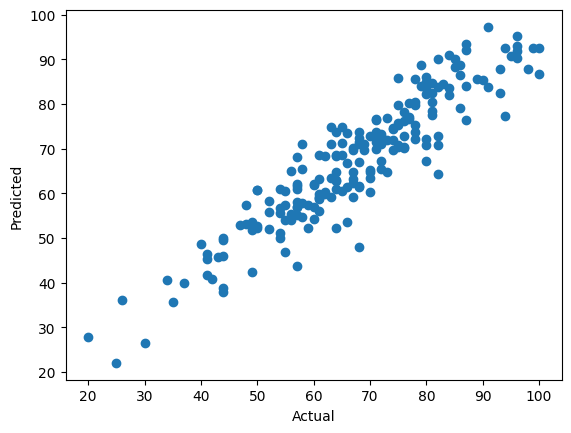

In [12]:
plt.scatter(y_test, y_pred)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.show()

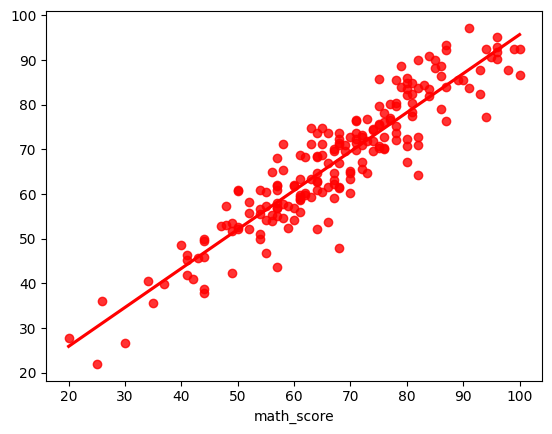

In [13]:
sns.regplot(x=y_test, y=y_pred, ci=None, color='red')
plt.show()

#### Difference between Actual and Predicted Values

In [14]:
pred_df = pd.DataFrame({'Actual Value': y_test, 'Predicted Value': y_pred, 'Difference': y_test - y_pred})
pred_df

,Actual Value,Predicted Value,Difference
521,83,84.470534,-1.470534
737,57,55.134181,1.865819
740,80,83.617861,-3.617861
660,86,88.701225,-2.701225
411,55,54.095319,0.904681
...,...,...,...
408,54,56.658479,-2.658479
332,34,40.490031,-6.490031
208,78,72.070734,5.929266
613,41,45.271642,-4.271642
